# Minimax in 2048

How do heuristic weights and search depth affect score, tile reach, and time per move? Minimax plans for the worst legal position and value of the next tile. The simulator still spawns tiles randomly according to standard 2048 rules.

The heuristic rewards free cells and a large corner tile, and penalizes nonmonotonic rows and columns and large gaps between neighboring tiles. We select weights at depth one using simulated games, then evaluate them on a separate set of seeds. The depth comparison uses the team’s shared weights at both depths.

In [1]:
from dataclasses import asdict, replace
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

repo_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "agents" / "minimax.py").is_file()
)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from agents.heuristic import DEFAULT_WEIGHTS
from agents.minimax import MinimaxAgent
from game import play_games

tuning_seeds = range(2000, 2024)
test_seeds = range(3000, 3100)
assert set(tuning_seeds).isdisjoint(test_seeds)

plt.rcParams.update({
    "figure.dpi": 135,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "font.size": 10,
})
pd.set_option("display.max_columns", None)

Matplotlib is building the font cache; this may take a moment.


## Tune the heuristic

Each candidate changes one of the four shared weights. The baseline plus eight alternatives all play the same 24 tuning seeds at depth one. The highest mean final score selects the candidate. A tie keeps the first candidate in the list, which favors the shared baseline. This is a local search over weights, with no external dataset.

In [2]:
candidates = {"Shared defaults": DEFAULT_WEIGHTS}
for feature, values in {
    "empty": (0.5, 2.0),
    "monotonicity": (0.5, 2.0),
    "smoothness": (0.25, 1.0),
    "corner": (1.5, 4.5),
}.items():
    for value in values:
        candidates[f"{feature} = {value:g}"] = replace(DEFAULT_WEIGHTS, **{feature: value})


def collect_games(configuration, depth, weights, seeds):
    results = play_games(MinimaxAgent(depth, weights), seeds)
    return pd.DataFrame([
        {
            "configuration": configuration,
            "depth": depth,
            **asdict(game),
            "reached_2048": game.reached_2048,
        }
        for game in results
    ]).rename(columns={"total_time": "decision_time_s"})


tuning_games = pd.concat(
    [collect_games(label, 1, weights, tuning_seeds) for label, weights in candidates.items()],
    ignore_index=True,
)
tuning_scores = (
    tuning_games.groupby("configuration", sort=False)["score"]
    .mean()
    .sort_values(ascending=False, kind="stable")
)
selected = tuning_scores.index[0]
tuned_weights = candidates[selected]
tuning_table = pd.DataFrame.from_dict(candidates, orient="index")
tuning_table["mean_score"] = tuning_scores

display(tuning_table.loc[tuning_scores.index].round(2).rename_axis("Candidate"))
print(f"Selected on tuning games: {selected}")

,empty,monotonicity,smoothness,corner,mean_score
Candidate,,,,,
empty = 0.5,0.5,1.0,0.50,3.0,9522.67
empty = 2,2.0,1.0,0.50,3.0,9171.67
corner = 4.5,1.0,1.0,0.50,4.5,9066.50
smoothness = 1,1.0,1.0,1.00,3.0,8585.50
Shared defaults,1.0,1.0,0.50,3.0,8559.00
smoothness = 0.25,1.0,1.0,0.25,3.0,8296.50
corner = 1.5,1.0,1.0,0.50,1.5,8082.17
monotonicity = 0.5,1.0,0.5,0.50,3.0,7684.83
monotonicity = 2,1.0,2.0,0.50,3.0,6722.33


Selected on tuning games: empty = 0.5


## Evaluate on held-out games

Depth counts player moves and includes the tile spawn after each move. The shared depth-one and depth-two runs isolate search depth. The tuned depth-one run measures how the tuning choice transfers. When tuning selects the shared defaults, the notebook reuses that run.

All games continue until no legal move remains. The 2048 rate counts games that reached at least one 2048 tile. Move time is total time inside the agent divided by the number of moves across all games. It depends on the machine.

In [3]:
shared_d1 = "Depth 1 · shared"
tuned_d1 = "Depth 1 · tuned"
shared_d2 = "Depth 2 · shared"

shared_games = collect_games(shared_d1, 1, DEFAULT_WEIGHTS, test_seeds)
test_runs = [shared_games]
if tuned_weights != DEFAULT_WEIGHTS:
    test_runs.append(collect_games(tuned_d1, 1, tuned_weights, test_seeds))
test_runs.append(collect_games(shared_d2, 2, DEFAULT_WEIGHTS, test_seeds))
games = pd.concat(test_runs, ignore_index=True)

summary = games.groupby(["configuration", "depth"], sort=False).agg(
    games=("seed", "size"),
    mean_score=("score", "mean"),
    median_score=("score", "median"),
    best_score=("score", "max"),
    best_tile=("max_tile", "max"),
    games_reaching_2048=("reached_2048", "sum"),
    total_moves=("moves", "sum"),
    decision_time_s=("decision_time_s", "sum"),
)
summary["reached_2048_pct"] = 100 * summary["games_reaching_2048"] / summary["games"]
summary["ms_per_move"] = 1000 * summary["decision_time_s"] / summary["total_moves"]
summary = summary.drop(columns=["total_moves", "decision_time_s"])
display(summary.round({"mean_score": 1, "reached_2048_pct": 1, "ms_per_move": 3}))

,,games,mean_score,median_score,best_score,best_tile,games_reaching_2048,reached_2048_pct,ms_per_move
configuration,depth,,,,,,,,
Depth 1 · shared,1,100,8370.8,7782.0,20220,1024,0,0.0,0.205
Depth 1 · tuned,1,100,9020.2,7926.0,18200,1024,0,0.0,0.202
Depth 2 · shared,2,100,17591.1,16322.0,37344,2048,27,27.0,4.624


In [4]:
scores_by_seed = games.pivot(index="seed", columns="configuration", values="score")


def compare_scores(label, baseline):
    differences = (scores_by_seed[label] - scores_by_seed[baseline]).to_numpy()
    rng = np.random.default_rng(42)
    means = rng.choice(differences, size=(5000, len(differences)), replace=True).mean(axis=1)
    low, high = np.percentile(means, [2.5, 97.5])
    return {
        "comparison": f"{label} vs {baseline}",
        "mean_score_difference": differences.mean(),
        "95% interval low": low,
        "95% interval high": high,
    }


comparisons = [compare_scores(shared_d2, shared_d1)]
if tuned_d1 in scores_by_seed:
    comparisons.append(compare_scores(tuned_d1, shared_d1))
display(pd.DataFrame(comparisons).set_index("comparison").round(1))

,mean_score_difference,95% interval low,95% interval high
comparison,,,
Depth 2 · shared vs Depth 1 · shared,9220.2,7339.5,11190.5
Depth 1 · tuned vs Depth 1 · shared,649.3,-525.0,1788.8


The intervals above use 5,000 bootstrap resamples of the per-seed score differences. Each pair starts from the same seed, and its games can diverge after the agents choose different moves. The tuning sweep changes one weight at a time and does not measure interactions between weights. The tuned configuration was evaluated only at depth one.

## Visualize and export

The figure shows how scores vary across seeds, which tile thresholds the agents reach, and how much time they spend choosing moves. The notebook exports the figure and both held-out tables for use in the slides or report.

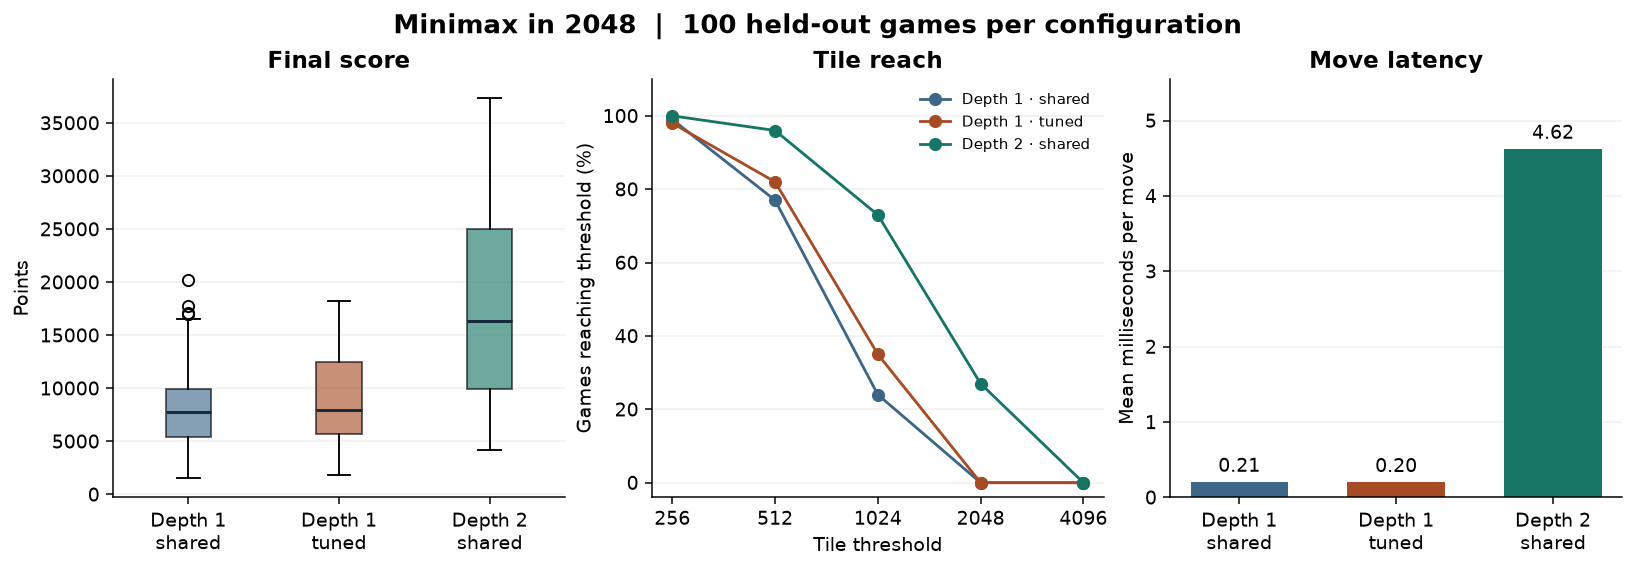

In [5]:
groups = list(games.groupby("configuration", sort=False))
colors = {shared_d1: "#3B6687", tuned_d1: "#A64C24", shared_d2: "#167565"}
short_labels = {
    shared_d1: "Depth 1\nshared",
    tuned_d1: "Depth 1\ntuned",
    shared_d2: "Depth 2\nshared",
}
labels = [short_labels[name] for name, _ in groups]
positions = range(1, len(groups) + 1)
tile_targets = [256, 512, 1024, 2048, 4096]

figure, (scores_ax, tiles_ax, time_ax) = plt.subplots(
    ncols=3, figsize=(12, 4.1), layout="constrained"
)
figure.suptitle(f"Minimax in 2048  |  {len(test_seeds)} held-out games per configuration",
                 fontsize=14, fontweight="bold")

boxes = scores_ax.boxplot(
    [group["score"] for _, group in groups],
    patch_artist=True,
    medianprops={"color": "#162A39", "linewidth": 1.6},
)
for box, (name, _) in zip(boxes["boxes"], groups):
    box.set_facecolor(colors[name])
    box.set_alpha(0.62)
scores_ax.set(title="Final score", ylabel="Points")
scores_ax.set_xticks(list(positions), labels)
scores_ax.grid(axis="y", alpha=0.2)
scores_ax.set_axisbelow(True)

for name, group in groups:
    rates = [(group["max_tile"] >= target).mean() * 100 for target in tile_targets]
    tiles_ax.plot(tile_targets, rates, marker="o", color=colors[name], label=name)
tiles_ax.set_xscale("log", base=2)
tiles_ax.set_xticks(tile_targets, [str(tile) for tile in tile_targets])
tiles_ax.set(title="Tile reach", xlabel="Tile threshold", ylabel="Games reaching threshold (%)")
tiles_ax.set_ylim(-4, 110)
tiles_ax.grid(axis="y", alpha=0.2)
tiles_ax.legend(frameon=False, fontsize=8, loc="upper right")

bars = time_ax.bar(
    list(positions), summary["ms_per_move"], color=[colors[name] for name, _ in groups],
    width=0.62,
)
time_ax.bar_label(bars, fmt="%.2f", padding=3)
time_ax.set(title="Move latency", ylabel="Mean milliseconds per move")
time_ax.set_xticks(list(positions), labels)
time_ax.set_ylim(0, summary["ms_per_move"].max() * 1.2)
time_ax.grid(axis="y", alpha=0.2)
time_ax.set_axisbelow(True)

results_dir = repo_root / "experiments" / "results"
figures_dir = repo_root / "experiments" / "figures"
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
games.to_csv(results_dir / "minimax_games.csv", index=False, float_format="%.8f")
summary.to_csv(results_dir / "minimax_summary.csv", float_format="%.6f")
figure.savefig(figures_dir / "minimax_comparison.png", dpi=180, bbox_inches="tight")
plt.show()